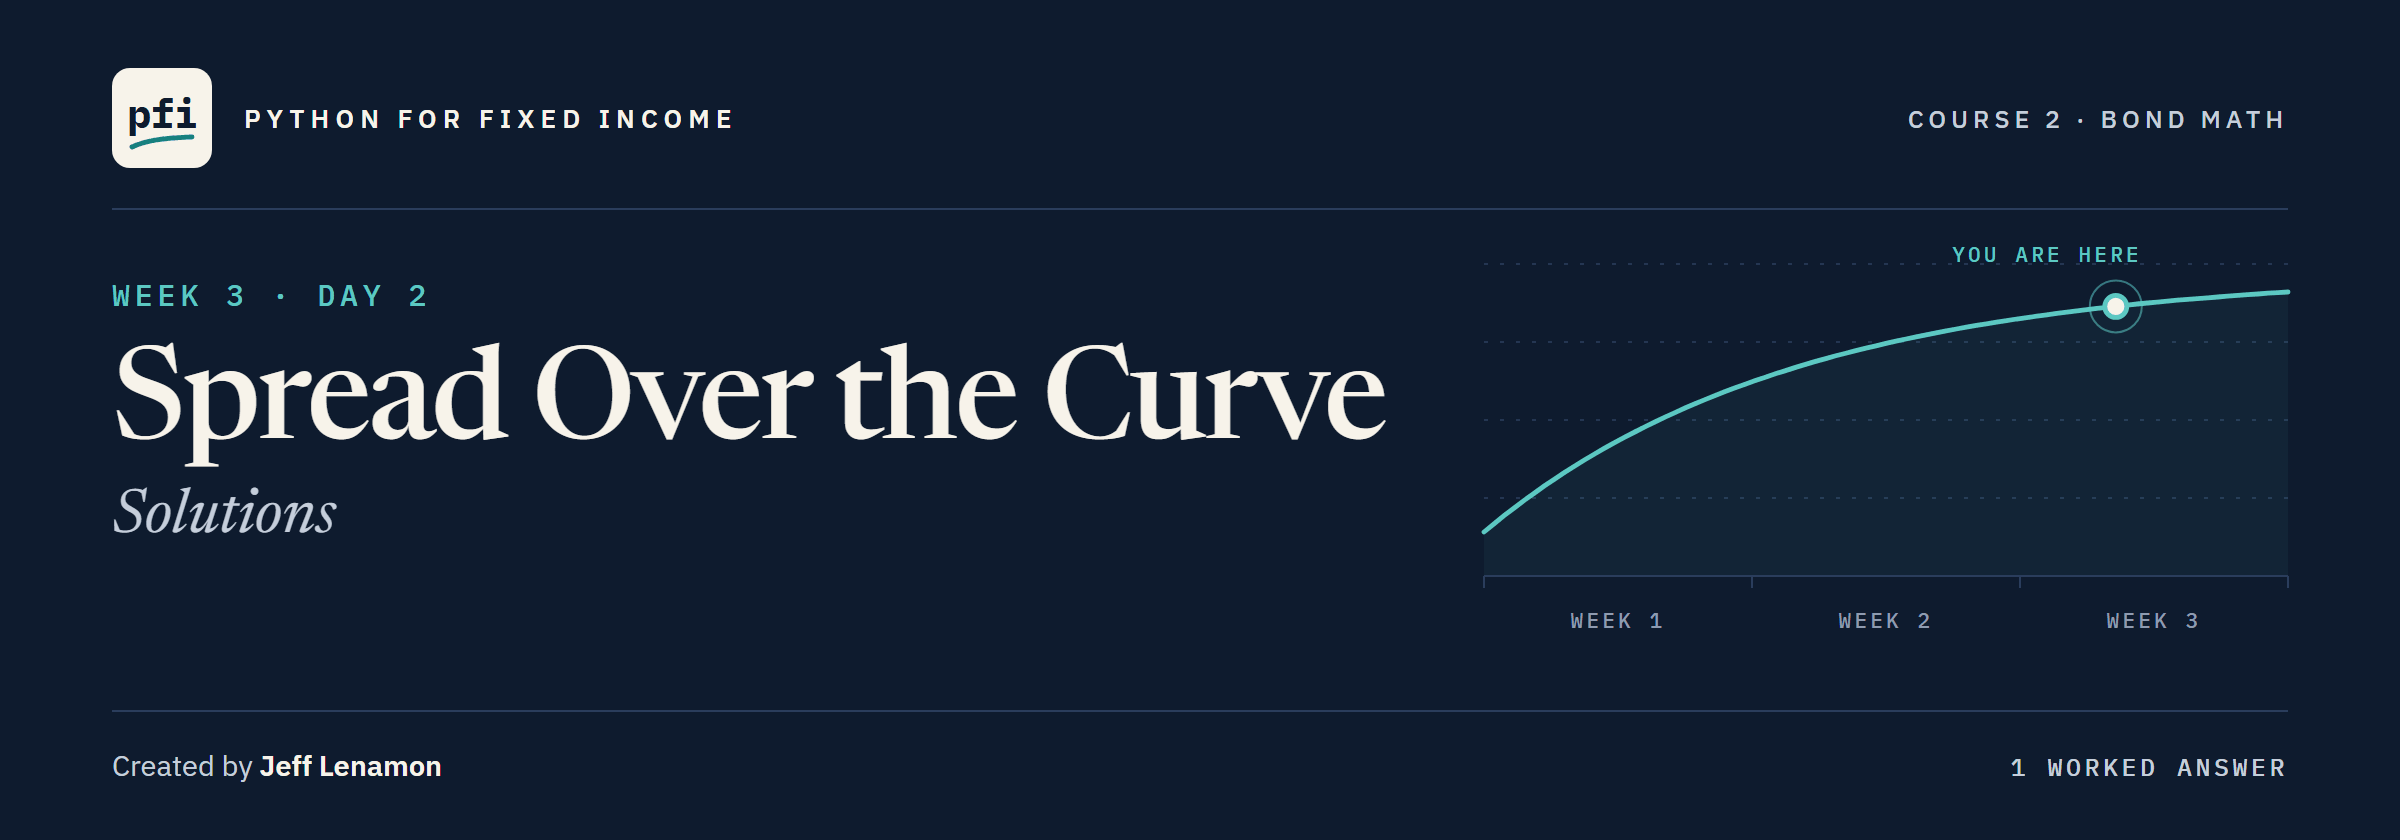

# Spread Over the Curve: Solutions

Week 3, Day 2. Worked answers to the exercises. Try each one yourself first.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course02_bond_math/week3/day2/12_spread_over_the_curve_solutions.ipynb)

## Exercises

Run the next cells first: the work folder with the module as this notebook ends it, the libraries and data, `check`, and the twenty bonds.

In [1]:
import os
import sys

# start_day.py sets up each day. On your machine Python finds it in the repo's start_of_day folder;
# in Colab there is no repo, so the cell downloads it from the course's GitHub page.
github = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/course02_bond_math/'
if os.path.exists('../../start_of_day/start_day.py'):
    sys.path.insert(0, '../../start_of_day')
else:
    !wget -q {github}start_of_day/start_day.py
from start_day import start_day

# a new work folder: the Excel files, and the module and its tests as notebook 12 ends.
# To start the day again, restart the kernel and run all cells.
work = start_day(12, after=12)

Work folder pfi_course2_12_k4w7q2xr: 6 data files, the module as notebook 12 left it, 12 commits, tagged week1 and week2


In [2]:
import importlib
import math

import bondmath
import pandas as pd

holdings = pd.read_csv('holdings.csv')
curve = pd.read_csv('course2_treasury_curve.csv')
curve_tenors = curve['tenor_years'].tolist()
curve_yields = curve['yield_pct'].tolist()
holdings['as_of_date'] = pd.to_datetime(holdings['as_of_date']).dt.date
holdings['maturity'] = pd.to_datetime(holdings['maturity']).dt.date
print(len(holdings), 'bonds,', len(curve_tenors), 'tenors')

200 bonds, 10 tenors


In [3]:
# check() compares your answer with the expected one and prints the result
def check(label, answer, expected):
    if answer is ...:
        print(label + ': not attempted yet')
        return
    if answer is None:
        print(label + ': not yet. Nothing came back: does your function end with return?')
        return
    # isinstance(x, list) is True when x is a list, so a list answer is compared value by value
    if isinstance(expected, list):
        correct = list(answer) == expected  # the same values in the same order
    # getattr(answer, 'ndim', 0) reads answer's ndim, its number of dimensions, as in NumPy
    # Part 1, and gives 0 when answer has none: a single number or a piece of text
    elif getattr(answer, 'ndim', 0) > 0:
        correct = False  # a column or a table where one value is expected
    elif isinstance(expected, float):
        # abs() drops the sign, so this is the size of the gap between the two decimals
        correct = abs(answer - expected) < 0.000001  # decimals: within a tiny tolerance
    else:
        correct = answer == expected
    print(label + ': correct' if correct else label + ': not yet. You have ' + str(answer))

In [4]:
# every 30th benchmark bond the book does not hold, twenty in all ([::30] steps 30 rows at a time)
benchmark = pd.read_csv('benchmark.csv')
not_held = benchmark[~benchmark['cusip'].isin(holdings['cusip'])]
twenty = not_held.iloc[::30].head(20).reset_index(drop=True)
twenty['as_of_date'] = pd.to_datetime(twenty['as_of_date']).dt.date
twenty['maturity'] = pd.to_datetime(twenty['maturity']).dt.date
ratings = pd.read_csv('ratings.csv')
print(len(twenty), 'bonds')

20 bonds


### Exercise 1

In [5]:
twenty['years'] = [bondmath.years_to_maturity(a, m)
                   for a, m in zip(twenty['as_of_date'], twenty['maturity'])]
twenty['spread_table_bp'] = [bondmath.spread_to_curve_bp(y, t, curve_tenors, curve_yields)
                             for y, t in zip(twenty['yield_pct'], twenty['years'])]
# the formula's one-point curve at each bond's own years
formula = [round(3.55 + 1.05 * (1 - math.exp(-t / 7)), 3) for t in twenty['years']]
spread_formula = [bondmath.spread_to_curve_bp(y, t, [t], [c])
                  for y, t, c in zip(twenty['yield_pct'], twenty['years'], formula)]
assert (pd.Series(spread_formula) - twenty['oas']).abs().max() < 1e-9
ex1_first_bp = twenty.loc[0, 'spread_table_bp']
ex1_largest_gap_bp = (twenty['spread_table_bp'] - twenty['oas']).max()
check('Exercise 1 first spread', ex1_first_bp, 122.71185185185188)
check('Exercise 1 largest gap', ex1_largest_gap_bp, 1.9533333333333616)

Exercise 1 first spread: correct
Exercise 1 largest gap: correct


Every one of the twenty reproduces its `oas`; on the table the largest gap is 1.95 bp.

### Exercise 2

In [6]:
with_bucket = twenty.merge(ratings[['rating', 'bucket', 'score']], on='rating', how='left')
# the best score in each bucket puts the buckets in rating order
by_bucket = (with_bucket.groupby('bucket')
             .agg(bonds=('cusip', 'count'), best_score=('score', 'min'),
                  mean_bp=('spread_table_bp', 'mean'))
             .sort_values('best_score').drop(columns='best_score'))
by_bucket.round(1)

,bonds,mean_bp
bucket,,
AA,1,54.4
A,6,80.6
BBB,8,151.5
BB,4,165.6
B,1,278.6


In [7]:
ex2_buckets = len(by_bucket)
ex2_bbb_mean_bp = by_bucket.loc['BBB', 'mean_bp']
check('Exercise 2 buckets', ex2_buckets, 5)
check('Exercise 2 BBB mean', ex2_bbb_mean_bp, 151.46441666666666)

Exercise 2 buckets: correct
Exercise 2 BBB mean: correct


In these twenty bonds the mean spread rises from bucket to bucket down the rating scale, as the file's generator built it; the table describes the data and ranks nothing.

### Exercise 3

In [8]:
%%writefile -a bondmath.py


def spread_change_bp(old_spread_bp: float, new_spread_bp: float) -> float:
    """Change from one spread to another, in basis points.

    Units: both spreads in bp; the result is in bp. Convention: new minus old, so a wider spread
    is a positive change. Excel: =new_cell-old_cell
    """
    return new_spread_bp - old_spread_bp

Appending to bondmath.py


In [9]:
%%writefile -a test_bondmath.py


def test_spread_change_bp_known_case():
    # worked by hand: 147 to 150 is 3 wider, 150 to 140 is 10 tighter
    assert bondmath.spread_change_bp(147.0, 150.0) == pytest.approx(3.0, abs=1e-12)
    assert bondmath.spread_change_bp(150.0, 140.0) == pytest.approx(-10.0, abs=1e-12)

Appending to test_bondmath.py


In [10]:
import subprocess
import sys

# python -m pytest -q with this notebook's own Python; -p no:cacheprovider: no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider', '--tb=no']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

....................................                                     [100%]
36 passed in 0.50s



In [11]:
importlib.reload(bondmath)
feskovar = holdings.loc[holdings['cusip'] == '99069RAD2'].iloc[0]
years = bondmath.years_to_maturity(feskovar['as_of_date'], feskovar['maturity'])
table_bp = bondmath.spread_to_curve_bp(feskovar['yield_pct'], years, curve_tenors, curve_yields)
ex3_change = bondmath.spread_change_bp(feskovar['oas'], table_bp)
check('Exercise 3 Feskovar change', ex3_change, 3.34800000000007)

Exercise 3 Feskovar change: correct


36 tests pass; Feskovar Devices is 3.348 bp wider on the table.

### Exercise 4: AI check

In [12]:
def assistant_spread_to_curve_bp(yield_pct, years, curve_tenors, curve_yields_pct):
    """Yield spread over a curve at the bond's own maturity, in basis points."""
    # the curve yield at the bond's own maturity
    curve_yield_pct = bondmath.interpolate_yield(years, curve_tenors, curve_yields_pct)
    # the fix: a gap in percent times 100 is the spread in basis points
    return (yield_pct - curve_yield_pct) * 100

In [13]:
excel_spread_bp = [147.41333333333327, 535.1541666666668, 153.5625, 218.5984999999999,
                   127.37129629629624]
holdings['years'] = [bondmath.years_to_maturity(a, m)
                     for a, m in zip(holdings['as_of_date'], holdings['maturity'])]
for i, expected in enumerate(excel_spread_bp):
    row = holdings.loc[i]
    result = assistant_spread_to_curve_bp(row['yield_pct'], row['years'],
                                          curve_tenors, curve_yields)
    assert abs(result - expected) < 1e-6, f"{row['cusip']}: {result:.6f}, Excel {expected}"
ex4_first_bp = assistant_spread_to_curve_bp(holdings.loc[0, 'yield_pct'], holdings.loc[0, 'years'],
                                            curve_tenors, curve_yields)
check('Exercise 4 Bezane Finance', ex4_first_bp, 147.41333333333327)

Exercise 4 Bezane Finance: correct


The assistant returned the gap in percent, 1.47, under a name and docstring that promise bp; the test from Excel caught it on the first row.

[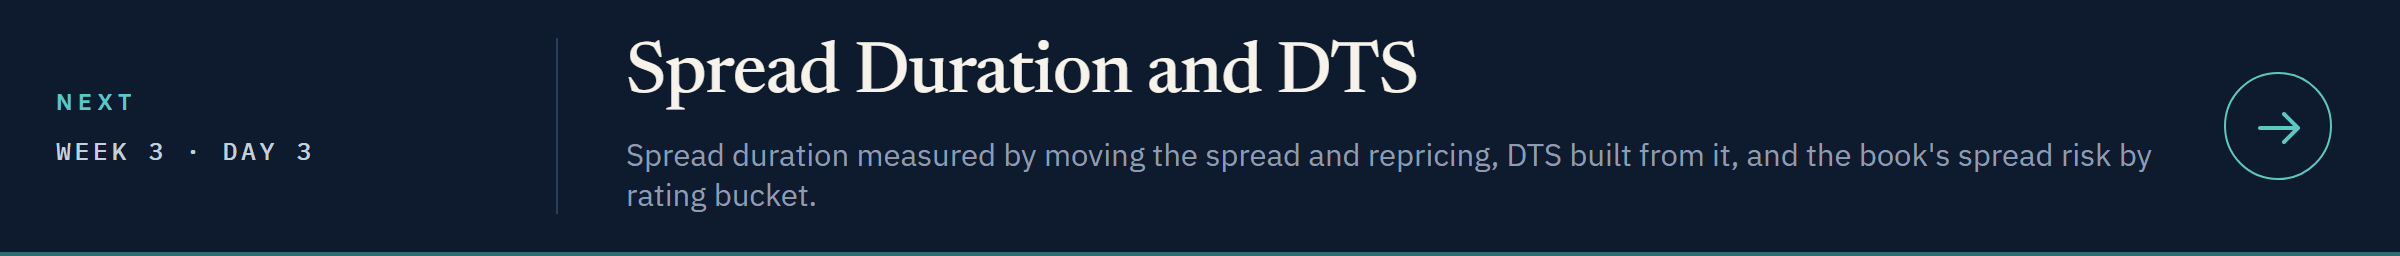](../day3/13_spread_duration_and_dts.ipynb)

[Open Day 3 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course02_bond_math/week3/day3/13_spread_duration_and_dts.ipynb)